# Numerical results: matrix vs tensor convolutional framelets

This notebook reproduces the two experiments in the numerical-results
section: image reconstruction and image denoising, comparing

* **univariate / matrix** convolutional framelets — vectorize the image,
  form a 1D Hankel (patch) matrix, truncate its SVD;
* **two-dimensional / tensor** convolutional framelets — form the order-4
  patch tensor and take a truncated HOSVD.

For each matrix rank, we pick the HOSVD 4-tuple whose
compression ratio (CR) is closest to the matrix CR.  Quality is then reported
as relative error (RE) while the denoising experiment also reports PSNR and SSIM.

**Environment:** `conda activate convFrame`.  Open from the repository
root or from `notebooks/`; the first code cell puts the package and the
experiment script on `sys.path`.  Shared loading, ranking, and figure
helpers live in `scripts/ConvFrameEX.py`.


## 0. Setup


In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd() if (Path.cwd() / "convframe").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
scripts = ROOT / "scripts"
if str(scripts) not in sys.path:
    sys.path.insert(0, str(scripts))

import ConvFrameEX as ex

print("package root:", ROOT)
print("experiment helpers:", ex.__file__)


package root: /Users/nfularczyk/Documents/Research/ConvFrame_work
experiment helpers: /Users/nfularczyk/Documents/Research/ConvFrame_work/scripts/ConvFrameEX.py


## 1. Metrics and parameters

The compression ratio is fixed to ensure a fair comparison between methods. We recall that
CR is the number of floating-point values in the uncompressed patch
array, H, divided by the number stored in the core plus factor matrices, S:

$$
\mathrm{CR}(f, H, S) = \frac{H_{\text{bytes}}}{S_{\text{bytes}}}.
$$

A higher CR is a more compressed representation.  Note that both sides use the
same dtype (`float64`), so counting entries is the same as counting
bytes.  Reconstruction quality is computed using the relative error

$$
\mathrm{RE}(f, \hat f) = \frac{\|f - \hat f\|_F}{\|f\|_F}.
$$

Images are loaded in \([0, 1]\) and
displayed as grayscale.  PSNR/SSIM use `data_range=1.0`, which gives the same values as
`data_range=255` on 8-bit images.


In [2]:
# --- Image size parameters ---
SIZE = 128
PATCH = SIZE // 4
# ---------------------------------


In [3]:
# Storage counts for heuristically selected ranks.
recon_r, recon_t = ex.heuristic_reconstruction_ranks(SIZE, PATCH)
denoise_r, denoise_t = ex.heuristic_denoising_ranks(SIZE, PATCH)
denoise_r = max(1, denoise_r)
print("Heuristic CRs:")
print(
    f"  recon r={recon_r} vs ({','.join(map(str, recon_t))}):  "
    f"{ex.matrix_cr(SIZE, PATCH, recon_r):.2f} vs {ex.tensor_cr(SIZE, PATCH, recon_t):.2f}"
)
print(
    f"  denoise r={denoise_r} vs ({','.join(map(str, denoise_t))}):  "
    f"{ex.matrix_cr(SIZE, PATCH, denoise_r):.2f} vs {ex.tensor_cr(SIZE, PATCH, denoise_t):.2f}"
)


Heuristic CRs:
  recon r=10 vs (96,96,24,24):  3.19 vs 3.15
  denoise r=2 vs (64,64,16,16):  15.97 vs 15.74


## 2. Load the test images

Boat and peppers are resized to \(N \times N\) using `SIZE` set in Section 1
(default \(N = 128\)), with patch size `PATCH` (default \(\ell = N/4 = 32\)).  Files are loaded using
`skimage.io.imread`, then scaled to a 2D float array in \([0, 1]\).


boat.png: range=[0.04, 0.91]
peppers_gray.tif: range=[0.02, 0.86]


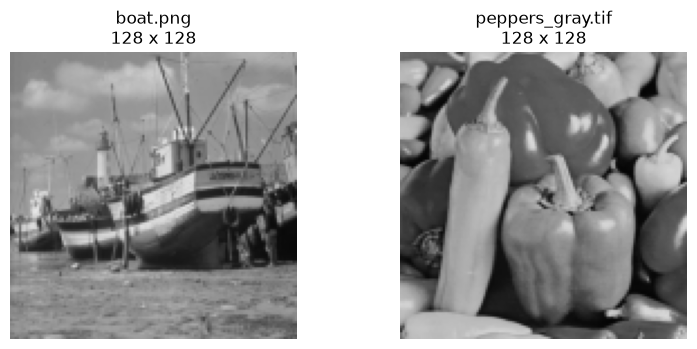

In [4]:
# --- Image parameters ---
IMAGE_PATHS = [
    ROOT / "data" / "boat.png",
    ROOT / "data" / "peppers_gray.tif",
]
# ---------------------------------

images = []
fig, axes = plt.subplots(1, len(IMAGE_PATHS), figsize=(8, 3.6))
for ax, path in zip(axes, IMAGE_PATHS):
    f = ex.load_grayscale(path, SIZE)
    images.append((path.stem, f))
    ax.imshow(f, cmap="gray", vmin=0.0, vmax=1.0)
    ax.set_title(f"{path.name}\n{f.shape[0]} x {f.shape[1]}")
    ax.axis("off")
    print(f"{path.name}: range=[{f.min():.2f}, {f.max():.2f}]")
fig.tight_layout()


## 3. Equal-CR rank matching

We choose a matrix
rank \(r\), and then we search every HOSVD 4-tuple \((r_0, r_1, r_2, r_3)\) with
\(r_0, r_1 \le N\) and \(r_2, r_3 \le \ell\), and keep the one whose CR is
closest to the matrix CR.  Ties prefer balanced tuples
(\(r_0 \approx r_1\), \(r_2 \approx r_3\)).
The heuristically found matrix ranks are \(N/12\) for reconstruction and \(N/50\)
for denoising: see `ex.reconstruction_ranks` / `ex.denoising_ranks`.

The table below runs this matching for every matrix rank
\(r = 1, \ldots, \min(N^2, \ell)\) and prints the matrix CR, the matched tensor
ranks, the tensor CR, and \(|\Delta\mathrm{CR}|\); the heuristic ranks are
starred.  To try a different rank, edit `RECON_MATRIX_RANK` or
`DENOISE_MATRIX_RANK` in the experiment cells below (Sections 4 and 5); the tensor ranks are
then re-matched to the same CR automatically.


In [5]:
import time

recon_r, recon_prefer = ex.heuristic_reconstruction_ranks(SIZE, PATCH)
denoise_r, denoise_prefer = ex.heuristic_denoising_ranks(SIZE, PATCH)
max_rank = min(SIZE * SIZE, PATCH)

t0 = time.perf_counter()
print(f"{'r':>4}  {'matrix CR':>10}  {'tensor ranks':>22}  {'tensor CR':>10}  {'|ΔCR|':>8}")
for r in range(1, max_rank + 1):
    prefer = {recon_r: recon_prefer, denoise_r: denoise_prefer}.get(r)
    m = ex.match_tensor_ranks(SIZE, PATCH, r, prefer=prefer)
    star = " *" if r in (recon_r, denoise_r) else ""
    print(
        f"{m.matrix_rank:4d}  {m.matrix_cr:10.2f}  {str(list(m.tensor_ranks)):>22}  "
        f"{m.tensor_cr:10.2f}  {m.abs_diff:8.2f}{star}"
    )
print(f"sweep time: {time.perf_counter() - t0:.2f} s")


   r   matrix CR            tensor ranks   tensor CR     |ΔCR|


   1       31.94         [84, 88, 4, 17]       31.94      0.00


   2       15.97        [48, 50, 18, 24]       15.97      0.00 *


   3       10.65        [58, 64, 15, 28]       10.65      0.00
   4        7.98        [47, 72, 22, 28]        7.98      0.00


   5        6.39        [65, 66, 19, 32]        6.39      0.00


...

  26        1.23      [110, 121, 32, 32]        1.23      0.00


  27        1.18      [117, 126, 30, 32]        1.18      0.00
  28        1.14      [112, 128, 32, 32]        1.14      0.00


  29        1.10      [116, 128, 32, 32]        1.10      0.00


  30        1.06      [120, 128, 32, 32]        1.06      0.00


  31        1.03      [124, 128, 32, 32]        1.03      0.00
  32        1.00      [128, 128, 32, 32]        1.00      0.00
sweep time: 1.83 s


## 4. Experiment 1 — reconstruction (Fig. 7)

Matrix rank is selected as \(N/12\) while the tensor ranks come
from the equal-CR matching of Section 3.  The tensor reconstruction should be sharper,
with a lower relative error.


matrix rank 10  CR=3.19
tensor ranks [95, 104, 23, 23]  CR=3.19
reconstructing boat ...



boat
  patch matrix  CR=3.19  RE=0.07
  patch tensor  CR=3.19  RE=0.04
reconstructing peppers_gray ...



peppers_gray
  patch matrix  CR=3.19  RE=0.08
  patch tensor  CR=3.19  RE=0.03


wrote /Users/nfularczyk/Documents/Research/ConvFrame_work/outputs/fig1_reconstruction.png


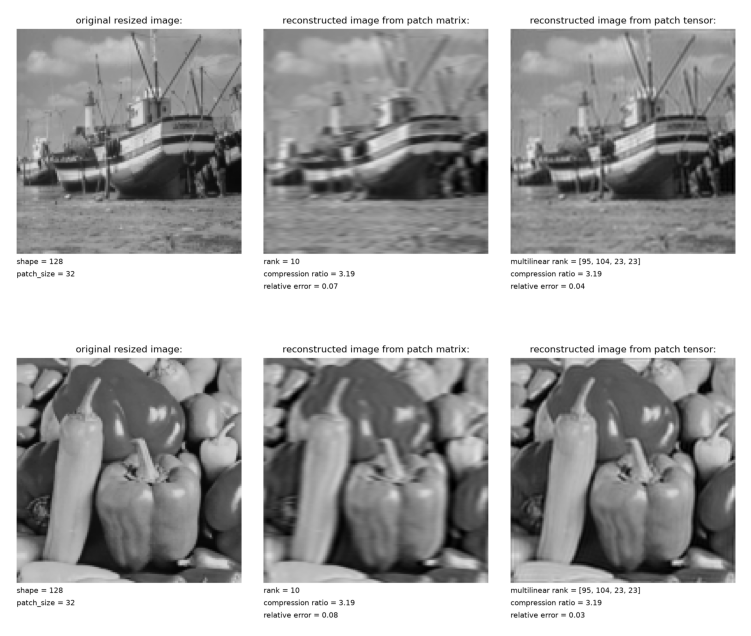

In [6]:
# --- Rank parameters ---
RECON_MATRIX_RANK = SIZE // 12      # editable; tensor ranks are re-matched to its CR
_, recon_prefer = ex.heuristic_reconstruction_ranks(SIZE, PATCH)
RECON_TENSOR_RANKS = ex.match_tensor_ranks(
    SIZE, PATCH, RECON_MATRIX_RANK, prefer=recon_prefer
).tensor_ranks
# ---------------------------------
print(
    f"matrix rank {RECON_MATRIX_RANK}  "
    f"CR={ex.matrix_cr(SIZE, PATCH, RECON_MATRIX_RANK):.2f}"
)
print(
    f"tensor ranks {list(RECON_TENSOR_RANKS)}  "
    f"CR={ex.tensor_cr(SIZE, PATCH, RECON_TENSOR_RANKS):.2f}"
)

recon_trials = []
for name, image in images:
    print(f"reconstructing {name} ...")
    trial = ex.run_reconstruction(
        image, PATCH, RECON_MATRIX_RANK, RECON_TENSOR_RANKS, name=name
    )
    recon_trials.append(trial)
    ex._report_reconstruction(trial)

recon_path = ROOT / "outputs" / "fig1_reconstruction.png"
ex.plot_reconstruction(
    recon_trials, PATCH, RECON_MATRIX_RANK, RECON_TENSOR_RANKS, recon_path
)
print("wrote", recon_path)

img = plt.imread(recon_path)
plt.figure(figsize=(12, 8))
plt.imshow(img)
plt.axis("off")
plt.show()


## 5. Experiment 2 — denoising (Fig. 8)

White Gaussian noise with standard deviation \(80\) on the 8-bit scale
(i.e. \(80/255\) in \([0, 1]\)) is added to the input image and clipped.  Both methods
approximate the *noisy* patch arrays. We then find RE, PSNR, and SSIM by measuring
against the clean input image.

Matrix rank is \(N/50\) while tensor ranks are CR-matched as in the previous experiment.
One of the advantages of keeping the image as a matrix, rather than vectorizing first, is that it preserves
spatial structure in the low-rank approximation of the patch tensor.


matrix rank 2  CR=15.97
tensor ranks [48, 50, 18, 24]  CR=15.97
sigma (8-bit) 80.0
denoising boat ...



boat
  patch matrix  CR=15.97  RE=0.19  PSNR=19.72  SSIM=0.37
  patch tensor  CR=15.97  RE=0.19  PSNR=19.99  SSIM=0.38
denoising peppers_gray ...



peppers_gray
  patch matrix  CR=15.97  RE=0.27  PSNR=17.21  SSIM=0.31
  patch tensor  CR=15.97  RE=0.20  PSNR=19.78  SSIM=0.50


wrote /Users/nfularczyk/Documents/Research/ConvFrame_work/outputs/fig2_denoising.png


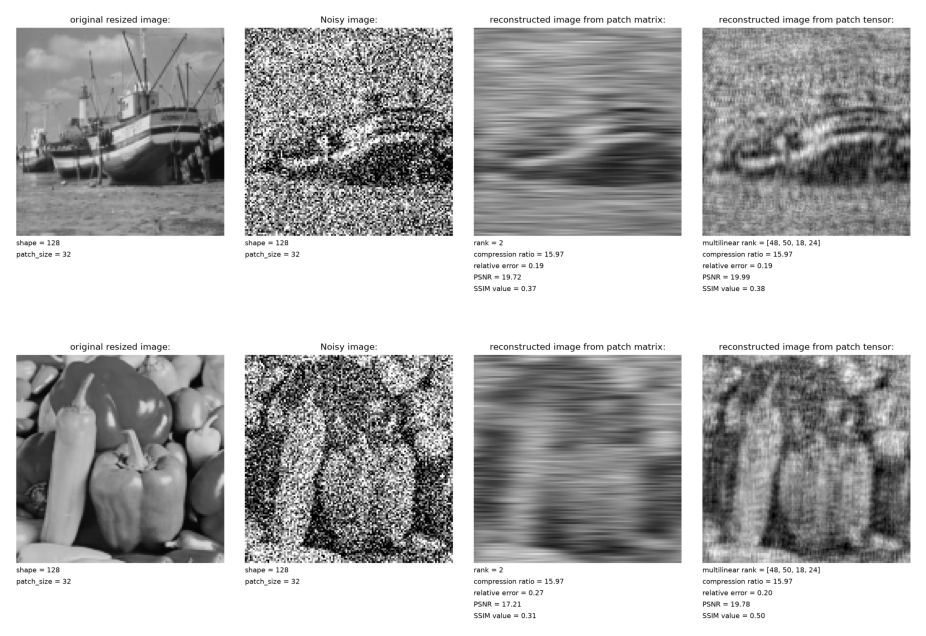

In [7]:
# --- Rank parameters (Noise experiment) ---
DENOISE_MATRIX_RANK = max(1, SIZE // 50)   # editable; tensor ranks are re-matched to its CR
_, denoise_prefer = ex.heuristic_denoising_ranks(SIZE, PATCH)
DENOISE_TENSOR_RANKS = ex.match_tensor_ranks(
    SIZE, PATCH, DENOISE_MATRIX_RANK, prefer=denoise_prefer
).tensor_ranks
SIGMA = 80.0          # 8-bit scale; internally divided by 255
SEED = 0
# ---------------------------------
print(
    f"matrix rank {DENOISE_MATRIX_RANK}  "
    f"CR={ex.matrix_cr(SIZE, PATCH, DENOISE_MATRIX_RANK):.2f}"
)
print(
    f"tensor ranks {list(DENOISE_TENSOR_RANKS)}  "
    f"CR={ex.tensor_cr(SIZE, PATCH, DENOISE_TENSOR_RANKS):.2f}"
)
print("sigma (8-bit)", SIGMA)

rng = np.random.default_rng(SEED)
denoise_trials = []
for name, image in images:
    print(f"denoising {name} ...")
    trial = ex.run_denoising(
        image,
        PATCH,
        DENOISE_MATRIX_RANK,
        DENOISE_TENSOR_RANKS,
        SIGMA,
        rng,
        name=name,
    )
    denoise_trials.append(trial)
    ex._report_denoising(trial)

denoise_path = ROOT / "outputs" / "fig2_denoising.png"
ex.plot_denoising(
    denoise_trials, PATCH, DENOISE_MATRIX_RANK, DENOISE_TENSOR_RANKS, denoise_path
)
print("wrote", denoise_path)

img = plt.imread(denoise_path)
plt.figure(figsize=(14, 8))
plt.imshow(img)
plt.axis("off")
plt.show()


## 6. Experimental Results

The tensor method should have lower relative error on
every image in Experiment 1, and higher PSNR / SSIM in Experiment 2 when the CRs are the same or 'close'.
The matrix reconstructions look more blurred because vectorizing mixes
the two spatial axes before computing the SVD while the HOSVD keeps a separate basis
along each mode of the patch tensor.
